In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('nasabah_raw.csv')
df_eks = pd.read_csv('data_kredit_eksternal.csv')
print(df.shape)
df.info()
df.head()

(1045, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1045 entries, 0 to 1044
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_Pelanggan            1045 non-null   object 
 1   Usia                    1045 non-null   float64
 2   Pendapatan_Bulanan      983 non-null    float64
 3   Skor_Kredit             1045 non-null   float64
 4   Lama_Bekerja_Thn        1003 non-null   float64
 5   Status_Pernikahan       1045 non-null   object 
 6   Tingkat_Pendidikan      1008 non-null   object 
 7   Status_Default          1045 non-null   int64  
 8   Pendapatan_Tahunan_Est  983 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 73.6+ KB


,ID_Pelanggan,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Pernikahan,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est
0,CUST-1001,58.0,10118000.0,542.0,13.0,Menikah,Magister,0,121416000.0
1,CUST-1002,48.0,10514000.0,331.0,20.0,Menikah,Sarjana,0,126168000.0
2,CUST-1003,34.0,13257000.0,690.0,22.0,Menikah,Magister,0,159084000.0
3,CUST-1004,27.0,10832000.0,576.0,7.0,Menikah,Sarjana,0,129984000.0
4,CUST-1005,-5.0,8295000.0,831.0,15.0,Single,SMA,0,99540000.0


In [4]:
print("Jumlah duplikat penuh:", df.duplicated().sum())
print(df[df.duplicated(keep=False)].sort_values('ID_Pelanggan').head(10))

df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

print("Sisa baris:", df.shape[0])

Jumlah duplikat penuh: 45
     ID_Pelanggan  Usia  Pendapatan_Bulanan  Skor_Kredit  Lama_Bekerja_Thn  \
59      CUST-1060  53.0          14765000.0        461.0               3.0   
1039    CUST-1060  53.0          14765000.0        461.0               3.0   
76      CUST-1077  34.0           6920000.0        510.0              22.0   
1011    CUST-1077  34.0           6920000.0        510.0              22.0   
96      CUST-1097  27.0          12499000.0        578.0               4.0   
1041    CUST-1097  27.0          12499000.0        578.0               4.0   
101     CUST-1102  43.0           7972000.0        365.0               6.0   
1026    CUST-1102  43.0           7972000.0        365.0               6.0   
1009    CUST-1137  -5.0                 NaN        580.0              11.0   
136     CUST-1137  -5.0                 NaN        580.0              11.0   

     Status_Pernikahan Tingkat_Pendidikan  Status_Default  \
59              Single                SMA             

In [5]:
print("Sebelum:", df['Status_Pernikahan'].unique())

df['Status_Pernikahan'] = df['Status_Pernikahan'].str.strip().str.title()

print("Sesudah:", df['Status_Pernikahan'].unique())
print(df['Status_Pernikahan'].value_counts())

Sebelum: ['Menikah' 'Single' 'single' 'Cerai' ' MENIKAH ']
Sesudah: ['Menikah' 'Single' 'Cerai']
Status_Pernikahan
Menikah    539
Single     379
Cerai       82
Name: count, dtype: int64


In [6]:
tidak_valid = (df['Usia'] < 17) | (df['Usia'] > 100)
print("Usia tidak valid:", tidak_valid.sum(), "baris, nilai:", df.loc[tidak_valid, 'Usia'].unique())

df.loc[tidak_valid, 'Usia'] = np.nan
print("Jumlah NaN pada Usia:", df['Usia'].isnull().sum())

Usia tidak valid: 35 baris, nilai: [ -5. 350.]
Jumlah NaN pada Usia: 35


**b.3 Mengapa koreksi Usia harus sebelum menghitung mean/median?**

Nilai seperti -5 dan 350 adalah kesalahan input, bukan data asli. Kalau tetap ikut dihitung, nilai itu menggeser statistik pusat (mean paling terpengaruh, dan posisi median pun ikut bergeser) sehingga hasilnya tidak mewakili usia nasabah sebenarnya. Kalau nilai tersebut kemudian dipakai untuk imputasi, kesalahannya ikut menyebar ke data yang lain. Dengan menjadikannya `NaN` lebih dulu, mean/median hanya dihitung dari usia yang valid, lalu `NaN`-nya diisi dari nilai yang wajar.

In [7]:
print("Dimensi sebelum merge:", df.shape)
df = df.merge(df_eks, on='ID_Pelanggan', how='left')

print("Dimensi setelah merge:", df.shape)
df.head()

Dimensi sebelum merge: (1000, 9)
Dimensi setelah merge: (1000, 11)


,ID_Pelanggan,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Pernikahan,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est,Pernah_Gagal_Bayar_Lain,Jumlah_Kartu_Kredit
0,CUST-1001,58.0,10118000.0,542.0,13.0,Menikah,Magister,0,121416000.0,Tidak,5.0
1,CUST-1002,48.0,10514000.0,331.0,20.0,Menikah,Sarjana,0,126168000.0,Tidak,3.0
2,CUST-1003,34.0,13257000.0,690.0,22.0,Menikah,Magister,0,159084000.0,Tidak,5.0
3,CUST-1004,27.0,10832000.0,576.0,7.0,Menikah,Sarjana,0,129984000.0,Ya,6.0
4,CUST-1005,NaN,8295000.0,831.0,15.0,Single,SMA,0,99540000.0,Ya,4.0


In [8]:
print((df.isnull().sum() / len(df) * 100).round(2))

ID_Pelanggan                0.0
Usia                        3.5
Pendapatan_Bulanan          6.0
Skor_Kredit                 0.0
Lama_Bekerja_Thn            4.0
Status_Pernikahan           0.0
Tingkat_Pendidikan          3.5
Status_Default              0.0
Pendapatan_Tahunan_Est      6.0
Pernah_Gagal_Bayar_Lain    15.0
Jumlah_Kartu_Kredit        15.0
dtype: float64


In [9]:
df['Usia'] = df['Usia'].fillna(df['Usia'].median())
df['Pendapatan_Bulanan'] = df['Pendapatan_Bulanan'].fillna(df['Pendapatan_Bulanan'].median())
df['Lama_Bekerja_Thn'] = df['Lama_Bekerja_Thn'].fillna(df['Lama_Bekerja_Thn'].median())
df['Jumlah_Kartu_Kredit'] = df['Jumlah_Kartu_Kredit'].fillna(0)
df['Tingkat_Pendidikan'] = df['Tingkat_Pendidikan'].fillna(df['Tingkat_Pendidikan'].mode()[0])
df['Pernah_Gagal_Bayar_Lain'] = df['Pernah_Gagal_Bayar_Lain'].fillna(df['Pernah_Gagal_Bayar_Lain'].mode()[0])
df['Pendapatan_Tahunan_Est'] = df['Pendapatan_Tahunan_Est'].fillna(df['Pendapatan_Bulanan'] * 12)
print(df.isnull().sum())
print("Total missing:", df.isnull().sum().sum())

ID_Pelanggan               0
Usia                       0
Pendapatan_Bulanan         0
Skor_Kredit                0
Lama_Bekerja_Thn           0
Status_Pernikahan          0
Tingkat_Pendidikan         0
Status_Default             0
Pendapatan_Tahunan_Est     0
Pernah_Gagal_Bayar_Lain    0
Jumlah_Kartu_Kredit        0
dtype: int64
Total missing: 0


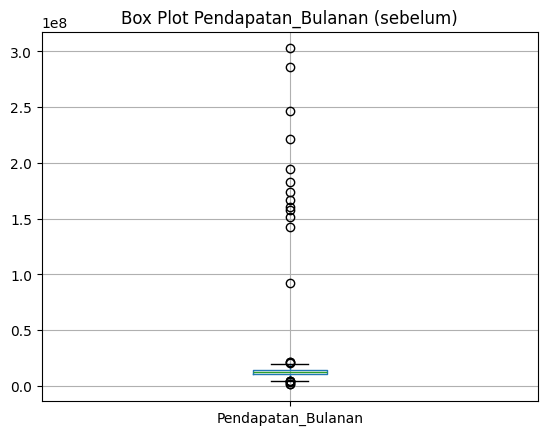

In [10]:
df.boxplot(column='Pendapatan_Bulanan')
plt.title('Box Plot Pendapatan_Bulanan (sebelum)')
plt.show()

In [11]:
Q1 = df['Pendapatan_Bulanan'].quantile(0.25)
Q3 = df['Pendapatan_Bulanan'].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR
print("Batas bawah:", batas_bawah)
print("Batas atas :", batas_atas)

outliers = df[(df['Pendapatan_Bulanan'] < batas_bawah) | (df['Pendapatan_Bulanan'] > batas_atas)]
print("Jumlah outlier:", len(outliers))

Batas bawah: 4329625.0
Batas atas : 19962625.0
Jumlah outlier: 22


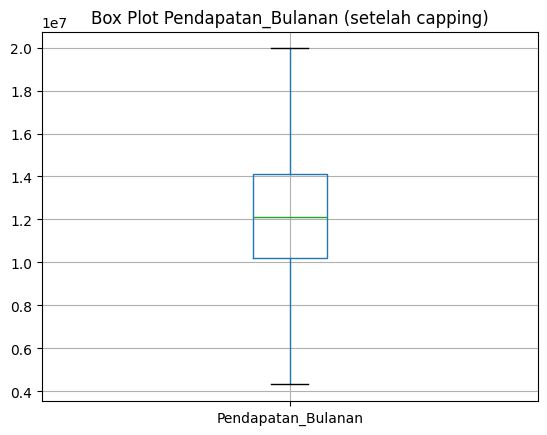

Jumlah baris: 1000


In [12]:
df['Pendapatan_Bulanan'] = df['Pendapatan_Bulanan'].clip(lower=batas_bawah, upper=batas_atas)
df['Pendapatan_Tahunan_Est'] = df['Pendapatan_Bulanan'] * 12
df.boxplot(column='Pendapatan_Bulanan')
plt.title('Box Plot Pendapatan_Bulanan (setelah capping)')
plt.show()
print("Jumlah baris:", df.shape[0])

**e.4 Konsekuensi negatif jika baris outlier dibuang (drop rows)**

1. **Kehilangan data nasabah**: setiap baris yang dibuang ikut membuang kolom lain (skor kredit, status default, dll.) yang sebenarnya valid, jadi informasi hilang percuma.
2. **Sampel jadi bias**: nasabah berpendapatan sangat tinggi itu mungkin nyata (bukan salah input). Kalau dibuang, model tidak pernah melihat kelompok ini dan kurang andal saat menemui nasabah serupa.
3. **Data yang sudah terbatas makin sedikit**: kelas gagal bayar (`Status_Default = 1`) adalah minoritas, jadi membuang baris berisiko mengurangi contoh kelas penting itu dan memperparah ketidakseimbangan.

Dengan capping, baris tetap ada, pengaruh nilai ekstrem tetap ditekan ke batas IQR.

In [13]:
df['Tingkat_Pendidikan'] = df['Tingkat_Pendidikan'].map({'SMA': 1, 'Sarjana': 2, 'Magister': 3})
df['Pernah_Gagal_Bayar_Lain'] = df['Pernah_Gagal_Bayar_Lain'].map({'Tidak': 0, 'Ya': 1})
df = pd.get_dummies(df, columns=['Status_Pernikahan'], drop_first=True, dtype=int)
df.drop(['ID_Pelanggan'], axis=1, inplace=True)
print(df.dtypes)
print("Total missing:", df.isnull().sum().sum())
df.head()

Usia                         float64
Pendapatan_Bulanan           float64
Skor_Kredit                  float64
Lama_Bekerja_Thn             float64
Tingkat_Pendidikan             int64
Status_Default                 int64
Pendapatan_Tahunan_Est       float64
Pernah_Gagal_Bayar_Lain        int64
Jumlah_Kartu_Kredit          float64
Status_Pernikahan_Menikah      int64
Status_Pernikahan_Single       int64
dtype: object
Total missing: 0


,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est,Pernah_Gagal_Bayar_Lain,Jumlah_Kartu_Kredit,Status_Pernikahan_Menikah,Status_Pernikahan_Single
0,58.0,10118000.0,542.0,13.0,3,0,121416000.0,0,5.0,1,0
1,48.0,10514000.0,331.0,20.0,2,0,126168000.0,0,3.0,1,0
2,34.0,13257000.0,690.0,22.0,3,0,159084000.0,0,5.0,1,0
3,27.0,10832000.0,576.0,7.0,2,0,129984000.0,1,6.0,1,0
4,41.0,8295000.0,831.0,15.0,1,0,99540000.0,1,4.0,0,1


In [14]:
X = df.drop('Status_Default', axis=1)
y = df['Status_Default']
kolom_numerik = ['Usia', 'Pendapatan_Bulanan', 'Skor_Kredit', 'Lama_Bekerja_Thn',
                 'Jumlah_Kartu_Kredit', 'Pendapatan_Tahunan_Est', 'Tingkat_Pendidikan']
fitur_tampil = ['Usia', 'Pendapatan_Bulanan', 'Skor_Kredit']
print("=== SEBELUM standardisasi ===")
print(X[fitur_tampil].describe().round(3))
scaler = StandardScaler()
X[kolom_numerik] = scaler.fit_transform(X[kolom_numerik])
print("=== SESUDAH standardisasi ===")
print(X[fitur_tampil].describe().round(3))

=== SEBELUM standardisasi ===
           Usia  Pendapatan_Bulanan  Skor_Kredit
count  1000.000        1.000000e+03     1000.000
mean     40.082        1.212750e+07      580.507
std      11.580        3.062611e+06      158.991
min      20.000        4.329625e+06      300.000
25%      30.000        1.019200e+07      440.750
50%      41.000        1.213200e+07      579.000
75%      50.000        1.410025e+07      722.250
max      59.000        1.996262e+07      849.000
=== SESUDAH standardisasi ===
           Usia  Pendapatan_Bulanan  Skor_Kredit
count  1000.000            1000.000     1000.000
mean     -0.000               0.000        0.000
std       1.001               1.001        1.001
min      -1.735              -2.547       -1.765
25%      -0.871              -0.632       -0.879
50%       0.079               0.001       -0.009
75%       0.857               0.644        0.892
max       1.634               2.560        1.690


In [15]:
hasil = pd.concat([X, y], axis=1)
hasil.to_csv('clean_nasabah_final.csv', index=False)

print("Dimensi akhir:", hasil.shape)
print("Total missing:", hasil.isnull().sum().sum())
hasil.head()


Dimensi akhir: (1000, 11)
Total missing: 0


,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Tingkat_Pendidikan,Pendapatan_Tahunan_Est,Pernah_Gagal_Bayar_Lain,Jumlah_Kartu_Kredit,Status_Pernikahan_Menikah,Status_Pernikahan_Single,Status_Default
0,1.548080,-0.656467,-0.242318,0.007777,1.591395,-0.656467,0,1.204949,1,0,0
1,0.684100,-0.527101,-1.570103,1.054639,0.148607,-0.527101,0,0.255423,1,0,0
2,-0.525473,0.368989,0.689020,1.353742,1.591395,0.368989,0,1.204949,1,0,0
3,-1.130259,-0.423216,-0.028362,-0.889534,0.148607,-0.423216,1,1.679712,1,0,0
4,0.079313,-1.252008,1.576308,0.306880,-1.294181,-1.252008,1,0.730186,0,1,0
